In [1]:
# Copyright (C) 2026 Advanced Micro Devices, Inc. All rights reserved.
#
# SPDX-License-Identifier: BSD-3-Clause
#
# Portions of this file consist of AI-generated content. AI-assisted
# content has been reviewed and validated by the authors.

# A digital twin of the SO-101, from first principles

A digital twin is only useful if code cannot tell it from the robot. That
reduces to three claims, each checked below with a measurement:

1. **It moves like the arm** - same command interface, same servo dynamics.
2. **It sees like the arm** - a camera rendered where the real one is mounted.
3. **It feels like the arm** - gripper current that comes from contact.

With those three checks done, you control the twin the way the full system
does. Section 4 is the console of `./run_pipeline.sh --digital-twin`: you
speak, Gemma 4 picks a behavior, and that behavior drives the twin.

What is simulated: the arm, its servos, the wrist camera and the table
scene (MuJoCo). What is real: everything above the arm transport - your
webcam and microphone, YOLOv26s pose, MediaPipe Hands, the mapper, Gemma 4
on the iGPU, and the behaviors. Sections 0 to 3 run inside this kernel.
In section 4 the twin becomes a ROS 2 node, the way the full system runs
it: this notebook connects to the launch `run_notebooks.sh` already started
and drives it with the arm client `01_behavior.ipynb` uses for the real
arm, so section 4 needs ROS 2.


## Compute placement

The pipeline is powered by AI models that utilize every subsystem of the APU. Each workload runs on the subsystem whose strengths best match its requirements.

<table style="border-collapse: collapse">
<thead>
<tr><th style="background-color: rgba(128, 128, 128, 0.2); border: 1px solid rgba(128, 128, 128, 0.4)">Task</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">Model or algorithm</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">What it does</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">Runs on</th><th style="border: 1px solid rgba(128, 128, 128, 0.4)">Runtime</th></tr>
</thead>
<tbody>
<tr style="background-color: rgba(0, 0, 0, 0)"><td rowspan="2" valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Voice control</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">Silero voice-activity detection</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">finds speech in the microphone audio</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">ONNX Runtime</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td style="border: 1px solid rgba(128, 128, 128, 0.4)">Gemma 4 E4B</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">speech → command</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">iGPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)"><code>llama.cpp</code> <code>llama-server</code> (HIP)</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td rowspan="2" valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Gestures</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">YOLOv26s-pose</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">finds your body and wrist</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">NPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">ONNX Runtime, VitisAI EP</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MediaPipe Hands</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">detects the hand gesture (pinch, roll)</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MediaPipe Tasks</td></tr>
<tr style="background-color: rgba(0, 0, 0, 0)"><td valign="top" style="background-color: rgba(128, 128, 128, 0.2); vertical-align: top; border: 1px solid rgba(128, 128, 128, 0.4)">Digital twin</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MuJoCo 3D simulation</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">simulates the arm and the table scene</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">CPU (rendering on the iGPU)</td><td style="border: 1px solid rgba(128, 128, 128, 0.4)">MuJoCo, EGL</td></tr>
</tbody>
</table>


In [2]:
# workshop bootstrap: the detector, hand tracker, Llama parser and dispatcher
# come from the finished reference code in solution/ (no TODO stubs). The twin
# itself is shared code in so101_sim/ and common/. The config then swaps the
# Feetech bus for the MuJoCo twin, in this kernel.
import sys, pathlib, threading, time

# find the solution/ folder and put it first on the import path
PROJECT = (pathlib.Path.cwd() / ".." / ".." / "solution").resolve()
assert (
    PROJECT / "config" / "workshop.yaml"
).exists(), f"solution not found at {PROJECT}"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
# run_pipeline.sh starts in this repo, so `import vla_pipeline` works there.
# This kernel starts in the notebook directory.
REPO = PROJECT.parents[1]
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# hide harmless warnings from other libraries
from common.quiet import hush_benign_warnings

hush_benign_warnings()  # silence known-benign third-party log noise

# Keep logger.info off the cell. Jupyter prints stderr in red, and that
# stream is where an info handler lands.
import logging
logging.getLogger().setLevel(logging.WARNING)

# images (OpenCV), arrays (NumPy), plots, and the buttons and text box used in section 4
import cv2, numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from common.ui_poll import ui_events  # jupyter_ui_poll's, with the stop button working on cells run meanwhile

# read the workshop settings, then switch them from the real arm to the twin
from common.config import load_config
from vla_pipeline.main import apply_sim_overrides

cfg = apply_sim_overrides(load_config())
LOAD_THRESHOLD = cfg["grip"]["load_threshold"]  # Present_Current counts the grip treats as contact (closing at Torque_Limit 500)


## 0. A body

The twin starts as a physics model: the SO-101's links, joints and
actuators (the open MJCF model), on a table with a few objects. MuJoCo
steps it 500 times per second on a CPU thread, locked to wall-clock time -
so one second of waiting is one second of simulated motion.

In [3]:
# build the simulated world - the arm, the table and the objects - and start it running
from common.motion import sim_world

world = sim_world(cfg)
# count what the physics model contains
m = world.model
print(f"{m.nbody} bodies, {m.njnt} joints, {m.nu} actuators, timestep {world.dt * 1000:.0f} ms")
print("detectable objects:", world.objects)

# wait one real second: the simulation clock should also move on by one second
t0, w0 = world.time, time.perf_counter()
time.sleep(1.0)
print(f"sim time advanced {world.time - t0:.3f} s in {time.perf_counter() - w0:.3f} s of wall time")

18 bodies, 10 joints, 6 actuators, timestep 2 ms
detectable objects: ['book', 'sports_ball', 'bottle', 'toothbrush']
sim time advanced 1.000 s in 1.000 s of wall time


## 1. It moves like the arm

`make_arm_backend(cfg)` returns `SimArmClient`, a subclass of the real
`LeRobotArm` in which only the LeRobot `SO101Follower` is swapped for a
simulated bus. Joint clamping, the goal-speed/acceleration register writes
and the current readback all run through the same code as on the rig.

Below the bus sits the part that matters physically: an STS3215 servo does
not jump to a goal. Its firmware accelerates, cruises and decelerates (a
trapezoidal profile), and the twin's servo model does the same. Command one
60° step and measure what comes back.

SimArmClient is a LeRobotArm: True
at rest: {'shoulder_pan': 0.0, 'shoulder_lift': -96.5, 'elbow_flex': 96.0, 'wrist_flex': 22.5, 'wrist_roll': 86.8, 'gripper': 38.0}
peak speed 131 deg/s, 95% of the step after 0.55 s


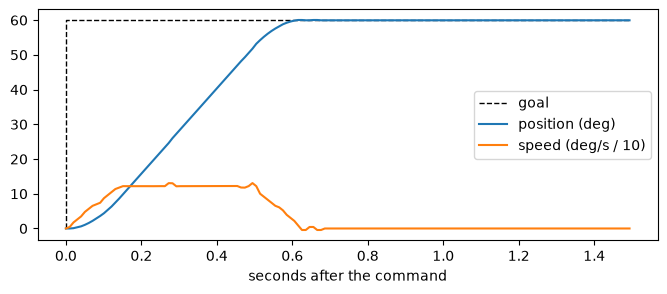

In [4]:
# the config says "sim", so this returns the twin; check it is the same class as the real arm
from common.motion import LeRobotArm, make_arm_backend

arm = make_arm_backend(cfg)
print(f"{type(arm).__name__} is a LeRobotArm: {isinstance(arm, LeRobotArm)}")
print("at rest:", {k: round(v, 1) for k, v in arm.get_joints().items()})


# give one joint a single goal, then read its angle 100 times a second
def step_response(joint, delta, seconds=1.5, hz=100):
    """Send one goal, then sample the joint - what a scope on the servo would show."""
    q0 = arm.get_joints()[joint]
    arm.send_joints({joint: q0 + delta})
    t, q, t0 = [], [], time.perf_counter()
    while (now := time.perf_counter() - t0) < seconds:
        t.append(now)
        q.append(arm.get_joints()[joint])
        time.sleep(1.0 / hz)
    return np.array(t), np.array(q) - q0


# turn the base 60 degrees; from the samples, get the top speed and the time to 95% of the turn
t, q = step_response("shoulder_pan", 60.0)
v = np.gradient(q, t)
t95 = t[np.argmax(q >= 0.95 * 60.0)]
print(f"peak speed {v.max():.0f} deg/s, 95% of the step after {t95:.2f} s")

# plot the goal (dashed), the angle, and the speed scaled down to fit
fig, ax = plt.subplots(figsize=(8, 3))
ax.step([0, 0, t[-1]], [0, 60, 60], "k--", lw=1, where="post", label="goal")
ax.plot(t, q, label="position (deg)")
ax.plot(t, v / 10, label="speed (deg/s / 10)")
ax.set_xlabel("seconds after the command")
ax.legend()
plt.show()
# back to the rest pose
arm.go_to_rest()

## 2. It sees like the arm

A camera is a pinhole at a pose. The twin's `wrist_cam` sits where the real
arm camera is mounted - beside the gripper, looking along the jaws - so it
moves with the wrist and sees what is being gripped. A render thread draws
every camera on the iGPU (EGL), separate from the physics thread, and
`SimCamera.read()` returns `(ok, bgr)` exactly like `cv2.VideoCapture`.

Present the open jaws, put the toothbrush between them, and look from both
the wrist and a free 3D view.

renderer: AMD Radeon Graphics (radeonsi, gfx1151, LLVM 20.1.2, DRM 3.64, 7.0.0-38-generic)


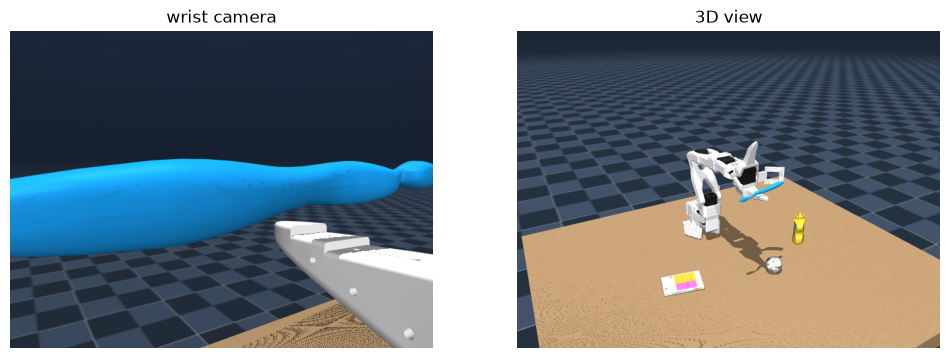

In [5]:
# simulated cameras, and the renderer that draws their images
from so101_sim import SimCamera
from so101_sim.render import shared_renderer

# joint angles (degrees) for a pose that presents the open jaws
PRESENT = {"shoulder_pan": 0.0, "shoulder_lift": -35.0, "elbow_flex": 30.0, "wrist_flex": 10.0, "wrist_roll": 0.0}

# two cameras, each read like a webcam: read() returns (ok, image)
wrist = SimCamera(world, "arm")  # the arm camera, on the wrist
view = SimCamera(world, "view", width=800, height=600)  # a free 3D view, for us

# move there with the jaws open, put the toothbrush between them, and take one picture from each camera
arm.go_to({**PRESENT, "gripper": 85.0})
time.sleep(1.0)  # let the jaws finish opening
world.stage_object("toothbrush", PRESENT)
_, w_img = wrist.read(fresh=True)
_, v_img = view.read(fresh=True)
print("renderer:", shared_renderer(world).renderer)

# show both pictures side by side (OpenCV images are BGR, matplotlib wants RGB)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, img, title in zip(axes, (w_img, v_img), ("wrist camera", "3D view")):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.show()
world.place("toothbrush", world.model.body("toothbrush").pos)  # back on the table

## 3. It feels like the arm

The real gripper has no touch sensor. The grip behavior infers contact from
the servo's `Present_Current`: closing on nothing, the motor reaches its
goal and the current falls away; closing on an object, the jaws stall and
the motor pushes against it, so the current stays high.

The twin produces that current from the physics - the actuator effort the
contact actually demands - not from a script. Close the jaws twice, once
empty and once on the ball, and compare against the threshold.

peak current - empty jaws: 201   ball: 200   (threshold 120)


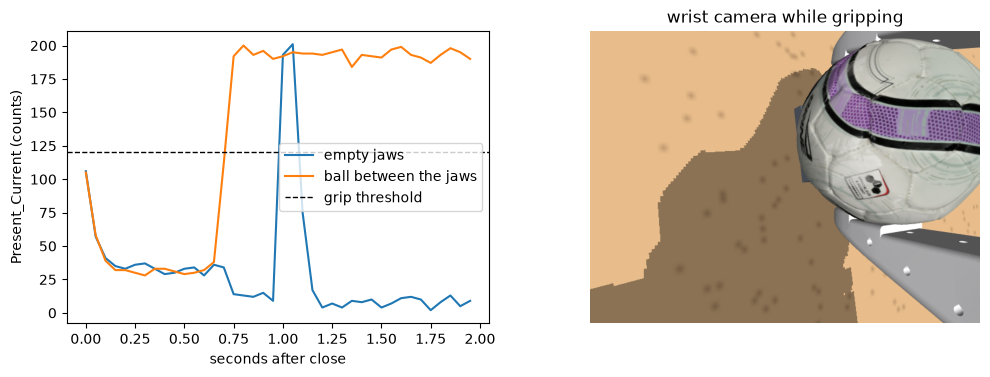

In [6]:
# the gripper angle sent as the "fully closed" goal
from common.motion import GRIPPER_CLOSED_FLOOR

# jaws at table height, closing sideways - how pick_place grasps the ball
GRASP = {"shoulder_pan": 0.0, "shoulder_lift": 9.0, "elbow_flex": 20.0, "wrist_flex": 54.0, "wrist_roll": 0.0}


# close the jaws at GRASP, with or without the ball between them, and record the gripper current
def squeeze(with_object, seconds=2.0, hz=20):
    """Open at GRASP, optionally place the ball, then return the current trace."""
    arm.go_to({**GRASP, "gripper": 85.0})
    time.sleep(1.0)
    if with_object:
        world.stage_object("sports_ball", GRASP)
    else:
        world.hide("sports_ball")
    arm.send_joints({"gripper": GRIPPER_CLOSED_FLOOR})
    trace = []
    for _ in range(int(seconds * hz)):
        time.sleep(1.0 / hz)
        trace.append(arm.get_gripper_load() or 0.0)
    _, img = wrist.read(fresh=True)
    arm.go_to({"gripper": 85.0})  # let go
    return np.array(trace), img


# close once on nothing and once on the ball; only the ball should keep the current above the threshold
empty, _ = squeeze(with_object=False)
held, held_view = squeeze(with_object=True)
print(f"peak current - empty jaws: {empty.max():.0f}   ball: {held.max():.0f}   (threshold {LOAD_THRESHOLD:.0f})")

# both current traces against the threshold, beside the wrist camera's view of the grip
fig, (ax, ax_img) = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(len(held)) / 20
ax.plot(t, empty, label="empty jaws")
ax.plot(t, held, label="ball between the jaws")
ax.axhline(LOAD_THRESHOLD, color="k", ls="--", lw=1, label="grip threshold")
ax.set_xlabel("seconds after close")
ax.set_ylabel("Present_Current (counts)")
ax.legend()
ax_img.imshow(cv2.cvtColor(held_view, cv2.COLOR_BGR2RGB))
ax_img.set_title("wrist camera while gripping")
ax_img.axis("off")
plt.show()
# world.model is the scene file, so this is the ball's home position in scene_vvla.xml
world.place("sports_ball", world.model.body("sports_ball").pos)
arm.go_to_rest()

## 4. Control the digital twin

Now you control the twin by voice or by typing, with the workshop's behaviors:

1. **Talk to the twin through ROS 2.** `run_notebooks.sh` already started it as a separate program, the same way `./run_pipeline.sh --digital-twin` does. This notebook only sends and receives messages.
2. **Watch you** through your webcam.
3. **Listen to you:** Gemma 4 hears the audio and picks a command.
4. **Take commands** in the live console.

`run_notebooks.sh` starts the twin before this kernel, with the same commands as `./run_pipeline.sh --digital-twin`:

`python -m so101_sim.stack --arm false --cameras true --digital-twin true --dry-run false`

`python -m so101_sim.stack --arm true --cameras false --digital-twin true --dry-run false`

The kernel is `python -m so101_sim.bringup kernel`. This cell only connects to that graph.


In [11]:
# connect to the twin run_notebooks.sh already started
from common.ros_helpers import ros2_available
from so101_sim import close_shared_world

assert ros2_available(), (
    "section 4 runs the twin as a ROS 2 node and needs rclpy: source /opt/ros/jazzy/setup.bash, "
    "then restart ./run_notebooks.sh"
)
from common.twin_ros import TwinSession

# close this kernel's in-process twin; the pipeline launch is already running
wrist.release()
view.release()
arm.close()
close_shared_world()
# connect the arm, the wrist camera, the 3D view and the scene
twin = TwinSession(cfg)
arm, wrist, view = twin.arm, twin.armcam, twin.view
print(f"arm: {type(arm).__name__} -> {cfg['robot']['command_topic']}")


arm: Ros2ArmClient -> /so101/joint_command


### Watching you

The next cell loads the pose and hand models, builds the console, and shows ten seconds of your webcam the way the two models see it. The frames come from the camera node `run_notebooks.sh` already started, on `/cameras/mount/image_raw`.

In [12]:
# your webcam, YOLO-pose and MediaPipe Hands, and the console that shows what they find
from common.twin_console import TwinConsole, jpeg, open_webcam
from models.vision import ObjectDetector

cam, pose, hands = open_webcam(cfg)
# The behaviors look up objects with this detector. The DDS participant
# already exists: run_notebooks.sh starts this kernel through so101_sim.bringup.
detector = ObjectDetector(cfg)
console = TwinConsole(arm, mount=cam, pose=pose, hands=hands, armcam=wrist, detector=detector,
                      view=view, load_threshold=LOAD_THRESHOLD)

# ten seconds of your webcam, as the two models see it
preview = widgets.Image(format="jpeg")
display(preview)
for _ in range(10 * 15):
    preview.value = jpeg(console.webcam_tiles())
    time.sleep(1 / 15)


Image(value=b'', format='jpeg')

### Listening to you

Your voice reaches the robot in three steps:

1. **Silero** (a small voice-activity network, CPU) and a loudness gate decide which microphone audio is speech. About once a second, the latest six seconds go to the model. There is no wait for silence.
2. **Gemma 4 E4B** (iGPU, through `llama-server`) hears that audio and answers with one robot command, for example `pick_place` with the object `ball`.
3. The **behavior** for that command runs on the arm. A new command stops the one that is running.

Typed "stop robot" stops the arm before the model is asked. A spoken "stop robot" is Gemma's `stop` command. "stop" alone does nothing. Noise is ignored. `handle_transcript` (TODO 3.2) makes these checks.

Which model hears you is `voice_intent` in `config/pipeline.yaml`. `gemma4-e4b-it` sends a hop of audio and does not wait for silence. This cell uses that same setting as `./run_pipeline.sh`.

The next cell starts the microphone and asks you for one command. It prints the command Gemma picked, and runs nothing yet. Without a microphone it uses a typed sentence; without the model files, a keyword match stands in.

In [13]:
# what every behavior gets: the config, the arm, the cameras and the models
from common.motion import mapper_from_config
from common.twin_voice import VoiceCommands
from integration.dispatch import WorkshopContext

ctx = WorkshopContext(
    cfg=cfg,
    arm=arm,
    camera=console.mount,  # behaviors and the console share the same webcam frames
    pose=pose,
    hands=hands,
    detector=detector,  # pick_place finds objects with it
    arm_camera=console.armcam,  # the twin's wrist camera, for grip and pick_place
    mapper=mapper_from_config(cfg),
    headless=True,  # behaviors draw into the console, never their own window
)
ctx.say = console.say  # robot speech lands in the voice panel
# the microphone and Gemma, and the queue that runs one command at a time
voice = VoiceCommands(cfg, ctx, console, twin)

# say one command: Gemma picks it, and nothing runs yet
voice.listen()

Say a command, for example "pick up the ball". Listening for 20 s...
Heard: "pick up the ball"
Gemma picked: pick_place (object: ball)


### Controlling the digital twin

Run the next cell, then try two things, in this order:

1. Say something that is not about the robot, for example "what's the weather like today". Gemma finds no command, the console says "I didn't catch a command in that.", and the arm does not move.
2. Say "wave at me". Gemma picks `wave`, and the arm waves.

Under the console, **stop** ends the cell and parks the arm, **reset** parks the arm and puts the objects back, and **end session** also ends the cell (run the cell again to resume). Saying "stop" only halts the behavior, so a later command in the same session still works. The notebook runs one cell at a time, so click **stop** or **end session** (or the kernel's stop button) before you run the clean-up cell.

| Say | What happens |
|---|---|
| "copy my movements" | The arm follows your right hand: where it is in the image, how close it is to the camera, its tilt, and your pinch for the gripper. |
| "pick up the ball" (or bottle, book, toothbrush) | The wrist camera finds the object; the arm grasps it, lifts it and holds it out. |
| "hold this" | The jaws close on what is between them and keep holding. If you then say "copy my movements", your pinch controls the gripper. |
| "release", "drop it" | The jaws open. |
| "wave", "dance" | The arm waves, or dances to a beat. |
| "go home" | The arm returns to its rest pose. |
| "stop robot" | Everything stops at once. "stop" alone does nothing. |

All commands: [Voice commands → behaviors](../../../README.md#voice-commands--behaviors).

In [ ]:
# the console image with its buttons and text box, redrawn FPS times a second 
FPS = 15
# Start with a frame, not empty: JupyterLab may not re-measure an image that grows later.
screen = widgets.Image(value=jpeg(console.compose()), format="jpeg", layout=widgets.Layout(width="1200px"))
stop = widgets.Button(description="stop", button_style="danger")
reset = widgets.Button(description="reset", button_style="warning")
typed = widgets.Text(placeholder="or type a command, then Enter", continuous_update=False,
                     layout=widgets.Layout(width="400px"))
end = widgets.Button(description="end session")
finished = threading.Event()  # set by stop or end session


def submit(change):
    """Enter in the text box sends the typed command, the same way as a spoken one."""
    text = change["new"].strip()
    if text:
        typed.value = ""
        voice.on_transcript(text)


def end_session(_=None):
    """Ends the loop below and the running behavior."""
    finished.set()
    ctx.stop_event.set()


stop.on_click(end_session)  # the red button ends the cell; saying "stop" only halts the behavior
reset.on_click(voice.reset_scene)
typed.observe(submit, names="value")
end.on_click(end_session)
display(widgets.VBox([screen, widgets.HBox([stop, reset, typed, end])]))

# run commands on their own thread, one at a time, and redraw the console until stop or end session
console.say("Ready. Try: 'copy my movements', 'hold this', 'pick up the ball', 'pick up the bottle', "
            "'pick up the toothbrush', 'wave', 'dance', 'go home' - or 'stop robot'.")
dispatcher = threading.Thread(target=voice.dispatch_loop, args=(finished,), daemon=True)
dispatcher.start()
try:
    # running this cell again while it runs (JupyterLab's run and advance) also ends the session
    with ui_events(on_rerun=end_session) as poll:
        while not finished.is_set():
            t0 = time.perf_counter()
            poll(10)  # deliver button clicks and typed commands while this cell runs
            screen.value = jpeg(console.compose())
            time.sleep(max(0.0, 1.0 / FPS - (time.perf_counter() - t0)))
finally:
    # stop, end session, or the kernel's stop button: stop the dispatcher, wait for the last behavior, park the arm
    finished.set()
    ctx.stop_event.set()
    dispatcher.join(timeout=10)
    arm.go_to_rest()
    print("session ended, arm parked")

Ready. Try: 'copy my movements', 'hold this', 'pick up the ball', 'pick up the bottle', 'pick up the toothbrush', 'wave', 'dance', 'go home' - or 'stop robot'.
Looking for a ball.
Got the sports ball.
Done.
Released.
Looking for a bottle.
Got the bottle.
Done.


### Running it outside the notebook

This section ran the finished TODO code in `workshop/solution/`. Your version is in `workshop/project/`, in the same files:

- `models/`: `npu.py` (TODOs 1.1-1.3), `hands.py` (1.4), `llm.py` (1.5-1.6)
- `ros/`: `arm_node.py` (2.4-2.6), `arm_client.py` (2.7-2.9)
- `integration/`: `dispatch.py` (3.1-3.2), `mimic.py` (3.3), `behaviors.py` (3.4)

To drive the twin with your version, run `python app.py --digital-twin` in `workshop/project/`.

## Clean up

Click **stop** or **end session** under the console (or the kernel's stop button) before you run this cell. It closes the microphone, the cameras and, if this notebook started it, Llama. The twin launch keeps running until `run_notebooks.sh` exits.

In [ ]:
# the console cell ended its session; this also ends a dispatcher it left running
finished.set()
ctx.stop_event.set()
dispatcher.join(timeout=5)
# close everything that holds a device or a process
voice.close()  # the microphone, and llama-server if this notebook started it
console.close()  # stops sharing the camera frames and closes both cameras
hands.close()
twin.close()  # the arm client, the 3D view, and the scene
print("twin closed")